# 06 · Zero-trust response: from alerts to graded network actions

**Input:** the deployed model from notebook 05 — federated XGBoost (FedXgbBagging, equal 1/n scaling, k-of-n gate) in `models/fed_xgb/` — plus `data/processed/hosts.csv` (device roles from `scripts/extract_dicom.py`).
**Question:** how should the network *act* on alerts so attacks are contained fast **without** cutting clinical imaging traffic on false alarms?

| Step | What | Why |
|---|---|---|
| 1 | Load the federated model, score every window | the same model the sites train together |
| 2 | **Calibrate** probabilities (temperature scaling on val) | the ladder uses probability thresholds, so they must mean what they say |
| 3 | **Per-host episode detection**: 1-of-1, 2-of-3 (notebook 02), **CUSUM**, **CUSUM with per-host reference** — tuned on val | one bad window should not isolate a scanner; persistent evidence should |
| 4 | **L0–L4 response ladder**: attack severity × confidence × duration, capped by **device criticality** | the PACS and imaging modalities are never cut off automatically |
| 5 | **Replay on the test traffic**: ladder vs **binary blocking** | time to contain, benign traffic restricted, clinical traffic blocked |
| 6 | **NIST SP 800-207 mapping** and enforcement commands (ipset + iptables + conntrack, TTL = fail-open) | how it runs on a real PEP |

Logged to MLflow, experiment **vitalgate-response**. Runtime ≈ 5–10 min.

In [1]:
# 0 · Setup
import os, sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta
import xgboost as xgb
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, MODELS = REPO / "data" / "processed", REPO / "models"
REP = REPO / "reports" / "response"; REP.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO / "src"))
import tracking, mlflow
import features as FV
tracking.use_experiment("vitalgate-response")
plt.rcParams["figure.dpi"] = 110

GAP_S     = 60       # a host silent for longer than this starts a new streak (same as notebook 02)
FP_BUDGET = 0.05     # max false alert episodes per wall-clock host-hour allowed when tuning detectors on val
TTL_S     = 60       # an action is held this long after the last alarm, then steps down one level (fail-open)
ESC_S     = 30       # an episode alarming for this long escalates one level
print("xgboost", xgb.__version__, "| session", tracking.SESSION)

xgboost 3.4.1 | session 20261115-000652


## 1 · Load the deployed federated model and score every window
`margin(x) = prior + Σ scale_u · trees_u(x)` — exactly the model saved in notebook 05. The polyglot (rule class) is not an ML class: a deterministic DPI rule (`preamble_exec`, the DICOM-preamble executable check) raises it, as decided in notebook 02.

In [2]:
CFG = json.loads((MODELS / "xgb_config.json").read_text(encoding="utf-8"))
MAN = json.loads((MODELS / "fed_xgb" / "manifest.json").read_text(encoding="utf-8"))
FEATURES, CLS = MAN["features"], MAN["classes"]; K = len(CLS); BEN = CLS.index("benign")
assert FEATURES == CFG["features"], "models/fed_xgb and xgb_config.json use different feature lists - re-run notebook 05"
RULE_CLASS = CFG["rule_class"]
PRIOR = np.array(MAN["prior"], np.float32)

def dmat(Xa, margin=None):
    if margin is None: return xgb.DMatrix(Xa)
    try:    return xgb.DMatrix(Xa, base_margin=margin)
    except Exception: return xgb.DMatrix(Xa, base_margin=margin.ravel())

UPDATES = []
for u in MAN["updates"]:
    b = xgb.Booster(); b.load_model(str(MODELS / "fed_xgb" / u["file"])); UPDATES.append((b, float(u["scale"])))

def fed_margin(Xa):
    m, z = np.tile(PRIOR, (len(Xa), 1)), np.zeros((len(Xa), K), np.float32)
    for b, sc in UPDATES:
        m += sc * b.predict(dmat(Xa, z), output_margin=True).reshape(len(Xa), K)
    return m

win = pd.read_parquet(PROC / "windows_v2.parquet")
d = FV.add_history(win.reset_index(drop=True), "split_run")          # all windows, incl. the rule class
X = d[FEATURES].to_numpy(np.float32)
LBL = d["label_class"].astype(str).values
TR, VA, TE = [(d["split_run"] == p).values for p in ("train", "val", "test")]
ML = LBL != RULE_CLASS                                                  # windows the ML model is judged on
IPS, TS = d["client_ip"].astype(str).values, d["window_start"].astype(float).values
RUN = d["attack_run"].fillna("").astype(str).values if "attack_run" in d else np.array([""] * len(d))
RULE = (d["preamble_exec"].fillna(0).values > 0) if "preamble_exec" in d else np.zeros(len(d), bool)

M = fed_margin(X)
print(f"{len(UPDATES)} client updates | {len(FEATURES)} features ({CFG.get('feature_version')}) | {len(d):,} windows "
      f"| rule fires on {RULE.sum():,} windows ({(LBL[RULE] == RULE_CLASS).mean():.0%} of them polyglot)")

48 client updates | 83 features (v4) | 51,733 windows | rule fires on 989 windows (100% of them polyglot)


## 2 · Calibration (temperature scaling)
One scalar T divides the federated margins: `P = softmax(margin / T)`. T is fitted on **val** by minimising log-loss, then frozen. Reported on **test**: expected calibration error (ECE, 15 bins) and log-loss before/after.

,ECE_test,logloss_test
T=1 (raw),0.0201,0.0837
T=0.75,0.0041,0.0758


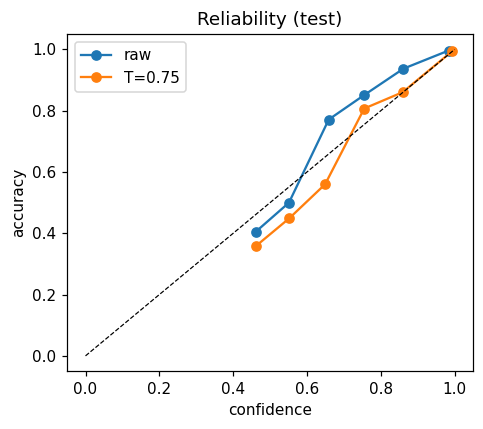

In [3]:
def softmax(m, T=1.0):
    z = m / T; e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)
yi = np.full(len(d), -1); ok = np.isin(LBL, CLS); yi[ok] = [CLS.index(c) for c in LBL[ok]]

def nll(mask, T):
    p = softmax(M[mask], T)[np.arange(mask.sum()), yi[mask]]; return float(-np.log(np.clip(p, 1e-12, 1)).mean())
def ece(mask, T, bins=15):
    p = softmax(M[mask], T); conf, pred = p.max(1), p.argmax(1); hit = pred == yi[mask]
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        s = (conf > lo) & (conf <= hi)
        if s.any(): e += s.mean() * abs(hit[s].mean() - conf[s].mean())
    return e

Ts = np.round(np.arange(0.5, 3.01, 0.05), 2)
VAL_ML, TE_ML = VA & ML, TE & ML
T_STAR = float(Ts[int(np.argmin([nll(VAL_ML, T) for T in Ts]))])
CAL = pd.DataFrame({"T=1 (raw)": {"ECE_test": ece(TE_ML, 1.0), "logloss_test": nll(TE_ML, 1.0)},
                    f"T={T_STAR}": {"ECE_test": ece(TE_ML, T_STAR), "logloss_test": nll(TE_ML, T_STAR)}}).T.round(4)
display(CAL)

fig, ax = plt.subplots(figsize=(4.5, 4))
for T, lab in [(1.0, "raw"), (T_STAR, f"T={T_STAR}")]:
    p = softmax(M[TE_ML], T); conf, hit = p.max(1), p.argmax(1) == yi[TE_ML]
    b = np.clip((conf * 10).astype(int), 0, 9)
    xs = [conf[b == i].mean() for i in range(10) if (b == i).sum() > 20]
    ys = [hit[b == i].mean() for i in range(10) if (b == i).sum() > 20]
    ax.plot(xs, ys, marker="o", label=lab)
ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.legend(); ax.set_title("Reliability (test)")
plt.tight_layout(); plt.savefig(REP / "calibration.png"); plt.show()

P = softmax(M, T_STAR)
SCORE = 1.0 - P[:, BEN]                                   # attack evidence of one window
PA = P.copy(); PA[:, BEN] = -1; ATK = np.array(CLS, dtype=object)[PA.argmax(1)]   # most likely attack class (object dtype: longer names fit)   # most likely attack class
SCORE[RULE], ATK[RULE] = 1.0, RULE_CLASS                  # the DPI rule overrides the model
FLAG = SCORE >= 0.5                                       # = argmax says "attack" (binary view)

## 3 · Per-host episode detection, tuned on val
For each host, windows are processed in time order (a silence > 60 s starts a new streak):
* **1-of-1** — act on every flagged window (no smoothing)
* **2-of-3** — notebook 02's rule
* **CUSUM** — `S = max(0, S + score − k)`; alarm while `S > h`. Weak evidence decays, persistent evidence accumulates.
* **CUSUM, per-host reference** — like CUSUM, but `k` is raised for hosts whose **benign** val traffic already scores high (noisy hosts such as bulk-transfer modalities). Hosts without enough benign history (e.g. the outside attackers) keep the global `k` — they are never made *more* sensitive, so missing history cannot act as an identity signal (the leak found in notebook 02).

Tuning on **val**: among settings with ≤ 0.05 false episodes per host-hour, maximise attack-run recall, then minimise median time to detect.

In [4]:
def wallclock_hours(mask, cap=GAP_S):
    t = pd.DataFrame({"ip": IPS[mask], "t": TS[mask]}).sort_values(["ip", "t"])
    return t.groupby("ip")["t"].diff().fillna(2.0).clip(upper=cap).sum() / 3600.0
HOURS = {"val": wallclock_hours(VA), "test": wallclock_hours(TE)}

def host_order(mask):
    idx = np.where(mask)[0]; return idx[np.lexsort((TS[idx], IPS[idx]))]

def detect(mask, kind, k=2, n=3, kref=0.3, h=1.0, kref_host=None):
    alarm = np.zeros(len(d), bool); prev_ip, prev_t, S, buf = None, -1e18, 0.0, []
    for i in host_order(mask):
        if IPS[i] != prev_ip or TS[i] - prev_t > GAP_S: S, buf = 0.0, []
        if kind == "kofn":
            buf = (buf + [FLAG[i]])[-n:]; a = sum(buf) >= k
        else:
            kr = kref_host.get(IPS[i], kref) if kref_host else kref
            S = max(0.0, S + SCORE[i] - kr); a = S > h
        alarm[i] = a or RULE[i]; prev_ip, prev_t = IPS[i], TS[i]
    return alarm

def episodes(mask, active, split_on_gap=True):
    """Episode id per window (-1 = none): consecutive active windows of one host (a silence > GAP_S splits it unless split_on_gap=False)."""
    ep = np.full(len(d), -1); cur, prev_ip, prev_t, prev_a = -1, None, -1e18, False
    for i in host_order(mask):
        new_streak = IPS[i] != prev_ip or (split_on_gap and TS[i] - prev_t > GAP_S)
        if active[i]:
            if new_streak or not prev_a: cur += 1
            ep[i] = cur
        prev_a, prev_ip, prev_t = bool(active[i]), IPS[i], TS[i]
    return ep

def evaluate(mask, alarm, part):
    ep = episodes(mask, alarm)
    E = pd.DataFrame({"ep": ep[mask], "benign": LBL[mask] == "benign"}); E = E[E.ep >= 0]
    false_eps = int((E.groupby("ep")["benign"].all()).sum()) if len(E) else 0
    R = pd.DataFrame({"run": RUN[mask], "lbl": LBL[mask], "t": TS[mask], "a": alarm[mask]})
    R = R[(R.run != "") & (R.lbl != "benign")]
    g = R.groupby("run")
    per = pd.DataFrame({"cls": g["lbl"].first(), "hit": g["a"].any(), "t0": g["t"].min(),
                        "t_hit": R[R.a].groupby("run")["t"].min()})
    per["ttd"] = per["t_hit"] - per["t0"] + 2
    return dict(false_episodes_per_h=false_eps / HOURS[part], run_recall=per["hit"].mean(), runs=len(per),
                runs_detected=int(per["hit"].sum()), median_TTD_s=per["ttd"].median(), p90_TTD_s=per["ttd"].quantile(0.9)), per

# per-host reference: 99th percentile of the host's benign VAL scores (>= 30 windows), never below the global k
bv = pd.DataFrame({"ip": IPS[VA & (LBL == "benign")], "s": SCORE[VA & (LBL == "benign")]})
HOST_Q = bv.groupby("ip")["s"].agg(lambda s: s.quantile(0.99) if len(s) >= 30 else np.nan).dropna()

def pick(rows):
    R = pd.DataFrame(rows); ok = R[R.false_episodes_per_h <= FP_BUDGET]
    R2 = ok if len(ok) else R.nsmallest(3, "false_episodes_per_h")
    return R2.sort_values(["run_recall", "median_TTD_s"], ascending=[False, True]).iloc[0]

tune = []
for kref in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    for h in [0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0]:
        for per_host in (False, True):
            kh = {ip: max(kref, q) for ip, q in HOST_Q.items()} if per_host else None
            r, _ = evaluate(VA, detect(VA, "cusum", kref=kref, h=h, kref_host=kh), "val")
            tune.append(dict(per_host=per_host, kref=kref, h=h, **r))
TUNE = pd.DataFrame(tune)
BEST_C = {ph: pick(TUNE[TUNE.per_host == ph].to_dict("records")) for ph in (False, True)}
display(pd.DataFrame(BEST_C).T[["kref", "h", "false_episodes_per_h", "run_recall", "median_TTD_s"]].rename(
    index={False: "CUSUM (global k)", True: "CUSUM (per-host k)"}).round(3))

,kref,h,false_episodes_per_h,run_recall,median_TTD_s
CUSUM (global k),0.6,0.5,0.045237,1.0,4.0
CUSUM (per-host k),0.1,0.5,0.045237,1.0,2.0


In [5]:
DETECTORS = {
    "1-of-1":               dict(kind="kofn", k=1, n=1),
    "2-of-3 (notebook 02)": dict(kind="kofn", k=2, n=3),
    "CUSUM":                dict(kind="cusum", kref=float(BEST_C[False].kref), h=float(BEST_C[False].h)),
    "CUSUM per-host":       dict(kind="cusum", kref=float(BEST_C[True].kref), h=float(BEST_C[True].h),
                                 kref_host={ip: max(float(BEST_C[True].kref), q) for ip, q in HOST_Q.items()}),
}
det_rows, ALARM_TE, PER_RUN = [], {}, {}
for name, p in DETECTORS.items():
    rv, _ = evaluate(VA, detect(VA, **p), "val")
    ALARM_TE[name] = detect(TE, **p); rt, PER_RUN[name] = evaluate(TE, ALARM_TE[name], "test")
    det_rows.append(dict(detector=name, val_false_eps_per_h=rv["false_episodes_per_h"], val_recall=rv["run_recall"], **rt))
DET = pd.DataFrame(det_rows).set_index("detector")
DET["runs_detected"] = [f"{r.runs_detected}/{r.runs}" for r in DET.itertuples()]
display(DET[["val_false_eps_per_h", "val_recall", "false_episodes_per_h", "runs_detected", "median_TTD_s", "p90_TTD_s"]].round(3))

ok = DET[DET.val_false_eps_per_h <= FP_BUDGET]
CHOSEN = (ok if len(ok) else DET).sort_values(["val_recall", "val_false_eps_per_h"], ascending=[False, True]).index[0]
ALARM = ALARM_TE[CHOSEN]
print(f"chosen on val: {CHOSEN}")
print("time to detect by class (test, chosen detector):")
display(PER_RUN[CHOSEN].groupby("cls").agg(runs=("hit", "size"), detected=("hit", "sum"), median_TTD_s=("ttd", "median")))

,val_false_eps_per_h,val_recall,false_episodes_per_h,runs_detected,median_TTD_s,p90_TTD_s
detector,,,,,,
1-of-1,1.176,1.0,0.741,126/126,2.0,2.0
2-of-3 (notebook 02),0.226,1.0,0.165,126/126,4.0,12.0
CUSUM,0.045,1.0,0.027,126/126,4.0,14.0
CUSUM per-host,0.045,1.0,0.247,126/126,2.0,4.0


chosen on val: CUSUM
time to detect by class (test, chosen detector):


,runs,detected,median_TTD_s
cls,,,
ae_bruteforce,18,18,4.0
assoc_flood,18,18,4.0
exfiltration,18,18,10.0
malformed_pdu,18,18,4.0
preamble_polyglot,18,18,2.0
ransomware_like,18,18,6.0
recon,18,18,4.0


## 4 · The L0–L4 response ladder
| Level | Action on the host | Typical trigger |
|---|---|---|
| **L0** | allow (normal zero-trust checks only) | no alarm |
| **L1** | **watch**: full packet logging, SOC ticket | low-severity or low-confidence alarm (e.g. a recon scan) |
| **L2** | **restrict**: rate-limit the host's DICOM traffic, page the on-call engineer | medium-severity alarm, or anything on the PACS |
| **L3** | **quarantine**: only the host's DICOM port to its own PACS stays open (rate-limited); all other traffic dropped, open connections reset | high-severity alarm (exfiltration, ransomware, polyglot) |
| **L4** | **isolate**: all traffic to and from the host dropped | high severity with high confidence on a non-clinical host |

**Level = severity × confidence**, +1 if the episode keeps alarming for ≥ 30 s, then **capped by device criticality**:

| Device (hosts.csv) | Criticality | Max automatic level | Why |
|---|---|---|---|
| PACS server | critical | **L2** | isolating the PACS stops imaging for the whole hospital: a human decides |
| Modality (CT, MR, DX, CR) | high | **L3** | a scanner keeps sending images to its PACS while everything else is blocked |
| Workstation | medium | L4 | |
| Outside host (`.99`) / unknown | low | L4 | |

Actions are held for `TTL_S` = 60 s after the last alarm, then step down one level per TTL: if the controller dies, every action expires on its own (**fail-open**, so a crashed controller cannot black out the hospital).
**Binary blocking** (the usual IDS → firewall baseline): any alarm → L4, same TTL, no device caps.

In [6]:
SEVERITY = {"recon": 1, "ae_bruteforce": 2, "assoc_flood": 2, "malformed_pdu": 2,
            "exfiltration": 3, "ransomware_like": 3, RULE_CLASS: 3}
CRIT_OF_ROLE = {"PACS server": "critical", "modality": "high", "workstation": "medium",
                "attacker (outside host)": "low", "unknown": "low"}
MAX_LEVEL = {"critical": 2, "high": 3, "medium": 4, "low": 4}
ROLE_OVERRIDE = {}                         # correct a host here, e.g. {"10.77.1.129": "modality"}

hp = PROC / "hosts.csv"
HOSTS = pd.read_csv(hp) if hp.exists() else pd.DataFrame(columns=["ip", "site", "suggested_role"])
ROLE = dict(zip(HOSTS["ip"].astype(str), HOSTS["suggested_role"].astype(str))); ROLE.update(ROLE_OVERRIDE)
def role_of(ip):
    return ROLE.get(ip) or ("PACS server" if ip.endswith(".10") else "attacker (outside host)" if ip.endswith(".99") else "unknown")
CRIT = {ip: CRIT_OF_ROLE.get(role_of(ip), "low") for ip in np.unique(IPS)}

def base_level(sev, conf):
    if sev >= 3: return 4 if conf >= 0.9 else 3
    if sev == 2: return 3 if conf >= 0.9 else 2
    return 2 if conf >= 0.9 else 1

def replay(mask, alarm, policy="ladder"):
    """Level in force at every window (host by host, in time order)."""
    level = np.zeros(len(d), int); prev_ip = None
    for i in host_order(mask):
        if IPS[i] != prev_ip:
            cur, last_alarm, last_step, ep_start, sev, confs = 0, -1e18, -1e18, None, 0, []
        if alarm[i]:
            if ep_start is None or TS[i] - last_alarm > GAP_S: ep_start, sev, confs = TS[i], 0, []
            sev = max(sev, SEVERITY.get(ATK[i], 1)); confs.append(SCORE[i]); last_alarm = last_step = TS[i]
            if policy == "binary":
                want = 4
            else:
                want = base_level(sev, float(np.mean(confs[-5:])))
                if TS[i] - ep_start >= ESC_S: want += 1
                want = min(want, 4, MAX_LEVEL[CRIT[IPS[i]]])
            cur = max(cur, want)                                   # never de-escalate during an active episode
        elif cur > 0:
            if policy == "binary":
                if TS[i] - last_alarm >= TTL_S: cur = 0
            else:                                                  # held one TTL, then one level down per TTL
                while cur > 0 and TS[i] - last_step >= TTL_S: cur -= 1; last_step += TTL_S
            if cur == 0: ep_start = None
        level[i] = cur; prev_ip = IPS[i]
    return level

LEVELS = {pol: replay(TE, ALARM, pol) for pol in ("binary", "ladder")}

## 5 · Replay on the test traffic: ladder vs binary blocking
* **Attack runs contained** — the host reached the level its attack calls for (L3 for severity-3 attacks, L2 for severity 2, L1 for recon), and **time to contain** from the run's first window.
* **Benign traffic restricted** — minutes of *benign* windows under L2 or higher, per wall-clock host-hour (all hosts, including compromised devices while they are under action).
* **Clinical traffic blocked** — minutes of benign windows of the PACS or modalities under **L4** (traffic fully cut), per host-hour. L3 keeps the DICOM path to the PACS open, so it does not count here.
* **False actions** — action episodes (level > 0) that contain no attack window, per host-hour.

In [7]:
NEED = {1: 1, 2: 2, 3: 3}
def response_metrics(level, part="test", mask=TE):
    hrs = HOURS[part]
    ben = mask & (LBL == "benign")
    clinical = np.array([CRIT[ip] in ("critical", "high") for ip in IPS])
    out = dict(benign_min_restricted_per_h=(ben & (level >= 2)).sum() * 2 / 60 / hrs,
               clinical_min_blocked_per_h=(ben & clinical & (level >= 4)).sum() * 2 / 60 / hrs)
    ep = episodes(mask, level > 0, split_on_gap=False)          # an action lasts until its level returns to 0
    E = pd.DataFrame({"ep": ep[mask], "benign": LBL[mask] == "benign"}); E = E[E.ep >= 0]
    out["false_actions_per_h"] = int(E.groupby("ep")["benign"].all().sum()) / hrs if len(E) else 0.0
    R = pd.DataFrame({"run": RUN[mask], "lbl": LBL[mask], "t": TS[mask], "lev": level[mask]})
    R = R[(R.run != "") & (R.lbl != "benign")]
    R["need"] = [NEED[SEVERITY.get(c, 1)] for c in R.lbl]; R["ok"] = R.lev >= R.need
    g = R.groupby("run")
    per = pd.DataFrame({"cls": g["lbl"].first(), "contained": g["ok"].any(), "t0": g["t"].min(),
                        "t_ok": R[R.ok].groupby("run")["t"].min(), "max_level": g["lev"].max()})
    per["ttc"] = per["t_ok"] - per["t0"] + 2
    k, n = int(per.contained.sum()), len(per)
    lo = beta.ppf(0.025, k, n - k + 1) if k > 0 else 0.0; hi = beta.ppf(0.975, k + 1, n - k) if k < n else 1.0
    out.update(runs_contained=f"{k}/{n} [{lo*100:.0f}, {hi*100:.0f}]", median_TTC_s=per.ttc.median(), p90_TTC_s=per.ttc.quantile(0.9))
    return out, per

res, PER_C = {}, {}
for pol, lev in LEVELS.items():
    res[pol], PER_C[pol] = response_metrics(lev)
RESP = pd.DataFrame(res).T
display(RESP[["runs_contained", "median_TTC_s", "p90_TTC_s", "benign_min_restricted_per_h", "clinical_min_blocked_per_h", "false_actions_per_h"]])

print("highest level reached per attack class (ladder):")
display(PER_C["ladder"].groupby("cls")["max_level"].value_counts().unstack(fill_value=0))
lv = pd.DataFrame({"level": LEVELS["ladder"][TE], "role": [role_of(ip) for ip in IPS[TE]], "benign": LBL[TE] == "benign"})
print("share of benign window-time per level, by device role (ladder):")
display((lv[lv.benign].groupby("role")["level"].value_counts(normalize=True).unstack(fill_value=0) * 100).round(2))

,runs_contained,median_TTC_s,p90_TTC_s,benign_min_restricted_per_h,clinical_min_blocked_per_h,false_actions_per_h
binary,"126/126 [97, 100]",4.0,14.0,0.100694,0.100694,0.027462
ladder,"126/126 [97, 100]",4.0,14.0,0.117171,0.0,0.027462


highest level reached per attack class (ladder):


max_level,2,3,4
cls,,,
ae_bruteforce,0,7,11
assoc_flood,0,5,13
exfiltration,0,4,14
malformed_pdu,0,8,10
preamble_polyglot,0,6,12
ransomware_like,0,7,11
recon,7,11,0


share of benign window-time per level, by device role (ladder):


level,0,1,2,3
role,,,,
modality,96.15,0.56,0.46,2.82
workstation,100.00,0.00,0.00,0.00


## 6 · One incident, step by step
The first test attack run on a **modality**, showing what the operator and the PEP see every 2 seconds.

In [8]:
DICOM_PORT = {"A": 4242, "B": 11112, "C": 4243}              # PACS listening port per site (from the pcaps)
PACS_IP = {s: ip for ip, s, r in HOSTS[["ip", "site", "suggested_role"]].itertuples(index=False) if r == "PACS server"}
SITE_OF = dict(zip(HOSTS["ip"].astype(str), HOSTS["site"].astype(str)))

PEP_SETUP = [   # installed once on the site gateway; per-host actions are just ipset entries with a timeout
    "ipset create vg_watch hash:ip timeout 0", "ipset create vg_rate hash:ip timeout 0",
    "ipset create vg_quar hash:ip timeout 0", "ipset create vg_iso hash:ip timeout 0",
    "iptables -I FORWARD 1 -m set --match-set vg_iso src -j DROP",
    "iptables -I FORWARD 1 -m set --match-set vg_iso dst -j DROP",
    "iptables -I FORWARD 1 -m set --match-set vg_quar src -j DROP",
    "iptables -I FORWARD 1 -m set --match-set vg_quar src -d <PACS_IP> -p tcp --dport <DICOM_PORT> "
    "-m hashlimit --hashlimit-upto 200/sec --hashlimit-mode srcip --hashlimit-name vg_quar -j ACCEPT",
    "iptables -I FORWARD 1 -m set --match-set vg_rate src -p tcp --dport <DICOM_PORT> "
    "-m hashlimit --hashlimit-above 50/sec --hashlimit-burst 100 --hashlimit-mode srcip --hashlimit-name vg_rate -j DROP",
    "iptables -I FORWARD 1 -m set --match-set vg_watch src -j NFLOG --nflog-group 7",
]
def enforcement(ip, level, ttl=TTL_S):
    """Commands the policy administrator sends to the PEP for one host. ipset timeouts make every action expire (fail-open)."""
    site = SITE_OF.get(ip, "?"); cmds = []
    if level >= 1: cmds.append(f"ipset add -exist vg_watch {ip} timeout {ttl}")
    if level == 2: cmds.append(f"ipset add -exist vg_rate {ip} timeout {ttl}")
    if level == 3: cmds += [f"ipset add -exist vg_quar {ip} timeout {ttl}   # DICOM to {PACS_IP.get(site, 'PACS')}:{DICOM_PORT.get(site, 104)} stays open",
                            f"conntrack -D -s {ip}"]
    if level == 4: cmds += [f"ipset add -exist vg_iso {ip} timeout {ttl}", f"conntrack -D -s {ip}", f"conntrack -D -d {ip}"]
    return cmds

mod_runs = [r for r in PER_C["ladder"].index if CRIT.get(pd.Series(IPS[TE & (RUN == r)]).mode()[0]) == "high"]
if mod_runs:
    r = mod_runs[0]; ip = pd.Series(IPS[TE & (RUN == r)]).mode()[0]
    t0 = TS[TE & (RUN == r)].min(); m = TE & (IPS == ip) & (TS >= t0 - 10) & (TS <= t0 + 90)
    o = host_order(m); lev = LEVELS["ladder"]; prev = 0
    print(f"run {r} | host {ip} ({role_of(ip)}, criticality {CRIT[ip]}, site {SITE_OF.get(ip)}) | true class {LBL[TE & (RUN == r)][0]}\n")
    for i in o:
        line = f"t={TS[i]-t0:+5.0f}s  true={LBL[i]:<16s} score={SCORE[i]:.2f}  alarm={int(ALARM[i])}  level=L{lev[i]}"
        if lev[i] != prev: line += "  ->  " + (" ; ".join(enforcement(ip, lev[i])) if lev[i] else "all actions expired (fail-open)")
        print(line); prev = lev[i]
else:
    print("no test attack run on a modality")

run A|10.77.1.130|1793181868.809 | host 10.77.1.130 (modality, criticality high, site A) | true class preamble_polyglot

t=   +0s  true=preamble_polyglot score=1.00  alarm=1  level=L3  ->  ipset add -exist vg_watch 10.77.1.130 timeout 60 ; ipset add -exist vg_quar 10.77.1.130 timeout 60   # DICOM to 10.77.1.10:4242 stays open ; conntrack -D -s 10.77.1.130
t=   +2s  true=preamble_polyglot score=1.00  alarm=1  level=L3
t=   +4s  true=preamble_polyglot score=1.00  alarm=1  level=L3
t=   +6s  true=preamble_polyglot score=1.00  alarm=1  level=L3
t=   +8s  true=preamble_polyglot score=1.00  alarm=1  level=L3
t=  +10s  true=preamble_polyglot score=1.00  alarm=1  level=L3
t=  +20s  true=preamble_polyglot score=1.00  alarm=1  level=L3
t=  +32s  true=preamble_polyglot score=1.00  alarm=1  level=L3
t=  +34s  true=preamble_polyglot score=0.47  alarm=1  level=L3


## 7 · Mapping to NIST SP 800-207 (zero-trust architecture)
| NIST 800-207 component | In VitalGate |
|---|---|
| **Policy Engine (PE)** — trust algorithm | section 4: calibrated federated-XGBoost score + attack class + episode duration + device criticality → level L0–L4, re-evaluated every 2-s window (continuous verification) |
| **Policy Administrator (PA)** | the controller that turns a level into `ipset add ... timeout` commands, refreshes them while the alarm persists, and lets them expire (section 6) |
| **Policy Enforcement Point (PEP)** | each site's gateway: `iptables` rules matching the `vg_*` ipsets, `conntrack -D` to cut open sessions |
| Data sources: **CDM / asset inventory** | `hosts.csv` (device role → criticality cap) |
| Data sources: **activity logs, threat signal** | the per-window DICOM/TCP features and the federated model's alerts (trained across hospitals without sharing traffic) |
| Data sources: **ID management / PKI** | AE titles and TLS certificates are checked at association time (out of scope of this notebook) |
| Tenet: *access granted per session, least privilege* | L3 keeps only the device's own clinical path (DICOM to its PACS) open |
| Tenet: *dynamic policy* | actions expire after a TTL and step down unless the evidence continues |

## 8 · Save the policy and log

In [9]:
POLICY = dict(
    model=dict(path="models/fed_xgb", feature_version=CFG.get("feature_version"), n_updates=len(UPDATES), temperature=T_STAR),
    detector=dict(name=CHOSEN, **{k: v for k, v in DETECTORS[CHOSEN].items() if k != "kref_host"},
                  per_host_k={ip: round(v, 4) for ip, v in DETECTORS[CHOSEN].get("kref_host", {}).items()}, gap_s=GAP_S),
    ladder=dict(severity=SEVERITY, base="sev3: L4 if conf>=0.9 else L3 | sev2: L3 if conf>=0.9 else L2 | sev1: L2 if conf>=0.9 else L1",
                escalate_after_s=ESC_S, ttl_s=TTL_S, fail_open=True),
    criticality=dict(role_to_criticality=CRIT_OF_ROLE, max_level=MAX_LEVEL, hosts=CRIT),
    enforcement=dict(pep_setup=PEP_SETUP, dicom_port=DICOM_PORT, pacs_ip=PACS_IP),
)
(MODELS / "response_policy.json").write_text(json.dumps(POLICY, indent=2, default=str), encoding="utf-8")
CAL.to_csv(REP / "calibration.csv", encoding="utf-8-sig"); TUNE.to_csv(REP / "cusum_tuning_val.csv", index=False, encoding="utf-8-sig")
DET.to_csv(REP / "detectors_test.csv", encoding="utf-8-sig"); RESP.to_csv(REP / "ladder_vs_binary_test.csv", encoding="utf-8-sig")
PER_C["ladder"].to_csv(REP / "runs_ladder_test.csv", encoding="utf-8-sig")
with tracking.run("Zero-trust response · ladder vs binary", params={"temperature": T_STAR, "detector": CHOSEN, "ttl_s": TTL_S, "esc_s": ESC_S},
                  tags={"stage": "response"}):
    tracking.log_metrics({"ECE_raw": CAL.iloc[0]["ECE_test"], "ECE_cal": CAL.iloc[1]["ECE_test"]})
    for pol in ("binary", "ladder"):
        r = RESP.loc[pol]
        tracking.log_metrics({"median_TTC_s": r["median_TTC_s"], "benign_min_restricted_per_h": r["benign_min_restricted_per_h"],
                              "clinical_min_blocked_per_h": r["clinical_min_blocked_per_h"], "false_actions_per_h": r["false_actions_per_h"]},
                             prefix=f"{pol}_")
    tracking.log_files(REP / "calibration.png", REP / "detectors_test.csv", REP / "ladder_vs_binary_test.csv", MODELS / "response_policy.json")
print("saved: models/response_policy.json, reports/response/")

saved: models/response_policy.json, reports/response/


## How to read it
* **Calibration:** ECE should drop after temperature scaling; the ladder's 0.9 confidence threshold relies on it.
* **Detectors:** the chosen one should keep val false episodes ≤ 0.05 per host-hour while detecting (nearly) every run; CUSUM usually trades a few seconds of detection time for far fewer false episodes than 1-of-1.
* **Ladder vs binary:** both should contain every attack; the ladder should need about the same time but block **far less clinical traffic** — binary blocking cuts a scanner off completely on every false alarm, the ladder never isolates the PACS or a modality automatically.
* Limitations to state: the replay uses the test windows as a time series (no live PEP), roles come from AE-title majority (correct them in `ROLE_OVERRIDE`), and actions on a compromised modality still restrict its benign traffic while the attack lasts.